**Run this notebook:** in Colab, choose **Runtime → Run all**. The first cell prepares METIS automatically using uv; a fresh runtime needs this setup again. These short tutorials use a CPU. Locally, select your [METIS Python environment](https://ojwatson.github.io/metis/basics/installing_metis.html).

The outputs below were generated when the documentation was built. [Source revision `b20b270c079a`](https://github.com/OJWatson/metis/tree/b20b270c079ad27a227a41b67828abcde7c74f87).

In [ ]:
#@title Prepare METIS (run once per runtime)
"""Embedded in notebook downloads: prepare their disposable Colab runtime with uv."""

import importlib
import importlib.metadata
import importlib.util
import io
import json
import os
from pathlib import Path
import platform
import re
import shutil
import subprocess
import sys
import tarfile
import urllib.request


UV_VERSION = "0.7.22"
INSTALL_GUIDE = "https://ojwatson.github.io/metis/basics/installing_metis.html"


def _installed_version(package):
    try:
        return importlib.metadata.version(package)
    except importlib.metadata.PackageNotFoundError:
        return None


def _compatible_pin(package, minimum, maximum=None):
    """Preserve compatible binary libraries already supplied by Colab."""
    version = _installed_version(package)
    if version is None:
        return None
    match = re.match(r"^(\d+)\.(\d+)(?:\.(\d+))?", version)
    if match is None:
        return None
    release = tuple(int(value or 0) for value in match.groups())
    if release < minimum or (maximum is not None and release >= maximum):
        return None
    return f"{package}=={version}"


def _uv_executable(directory):
    installed = shutil.which("uv")
    if installed:
        return installed
    destination = directory / "uv"
    if not destination.exists():
        architecture = {"x86_64": "x86_64", "aarch64": "aarch64"}.get(platform.machine())
        if architecture is None:
            raise RuntimeError(f"Unsupported Colab CPU architecture: {platform.machine()}")
        archive_name = f"uv-{architecture}-unknown-linux-gnu"
        url = (
            f"https://github.com/astral-sh/uv/releases/download/{UV_VERSION}/"
            f"{archive_name}.tar.gz"
        )
        with urllib.request.urlopen(url, timeout=120) as response:
            archive_bytes = response.read()
        with tarfile.open(fileobj=io.BytesIO(archive_bytes), mode="r:gz") as archive:
            # Read one known member, without extracting arbitrary archive paths.
            binary = archive.extractfile(f"{archive_name}/uv")
            if binary is None:
                raise RuntimeError("The uv release archive contains no executable")
            destination.write_bytes(binary.read())
        destination.chmod(0o755)
    return str(destination)


def _project_text(revision):
    dependencies = [
        f"metis-surrogate[plots,pandas] @ git+https://github.com/OJWatson/metis.git@{revision}",
        "torch==2.10.0",
    ]
    for package, minimum, maximum in [
        ("numpy", (2, 0, 0), (3, 0, 0)),
        ("matplotlib", (3, 9, 0), (4, 0, 0)),
        ("pandas", (2, 2, 0), (4, 0, 0)),
        ("pyarrow", (18, 0, 0), None),
        ("polars", (1, 37, 0), (3, 0, 0)),
    ]:
        pin = _compatible_pin(package, minimum, maximum)
        if pin:
            dependencies.append(pin)
    return (
        '[project]\nname = "metis-colab-tutorial"\nversion = "0.0.0"\n'
        f'requires-python = ">={sys.version_info.major}.{sys.version_info.minor},'
        f'<{sys.version_info.major}.{sys.version_info.minor + 1}"\n'
        f"dependencies = {json.dumps(dependencies)}\n\n"
        '[tool.uv]\npackage = false\n\n'
        '[tool.uv.sources]\ntorch = { index = "pytorch-cpu" }\n\n'
        '[[tool.uv.index]]\nname = "pytorch-cpu"\n'
        'url = "https://download.pytorch.org/whl/cpu"\nexplicit = true\n'
    )


def _metis_origin():
    try:
        return importlib.metadata.distribution("metis-surrogate").read_text("direct_url.json")
    except importlib.metadata.PackageNotFoundError:
        return None


def prepare_colab(revision):
    """Install only inside Colab; local notebooks use the selected METIS environment."""
    if not re.fullmatch(r"[a-f0-9]{40}", revision):
        raise ValueError("Notebook setup needs an exact 40-character source revision")
    try:
        in_colab = (
            importlib.util.find_spec("google.colab") is not None
            and bool(os.environ.get("COLAB_RELEASE_TAG") or os.environ.get("COLAB_BACKEND_VERSION"))
        )
    except ModuleNotFoundError:
        in_colab = False
    if not in_colab:
        if _installed_version("metis-surrogate") is None:
            raise RuntimeError(f"Select a Python environment containing METIS: {INSTALL_GUIDE}")
        print(f"Using local METIS {_installed_version('metis-surrogate')}.")
        return
    if sys.version_info < (3, 11):
        raise RuntimeError("This tutorial requires a Colab runtime with Python 3.11 or newer.")

    directory = Path("/content/.metis-notebooks")
    directory.mkdir(parents=True, exist_ok=True)
    (directory / "pyproject.toml").write_text(_project_text(revision), encoding="utf-8")
    loaded = {
        package: str(getattr(sys.modules[package], "__version__", _installed_version(package)))
        for package in ("numpy", "pandas", "torch", "matplotlib", "pyarrow", "polars")
        if package in sys.modules
    }
    metis_was_loaded = "metis" in sys.modules
    previous_metis_origin = _metis_origin()
    if metis_was_loaded:
        # Retain the import's identity if the user reruns setup after a restart
        # warning without actually restarting the Python process.
        previous_metis_origin = sys.modules["metis"].__dict__.setdefault(
            "_notebook_runtime_origin", previous_metis_origin,
        )
    environment = os.environ.copy()
    # Colab is a disposable runtime. Keep its unrelated packages and its active
    # notebook interpreter, instead of adding a second environment to sys.path.
    environment["UV_PROJECT_ENVIRONMENT"] = sys.prefix
    environment.pop("VIRTUAL_ENV", None)
    print("Preparing this Colab runtime with uv (CPU tutorial environment)…")
    result = subprocess.run(
        [_uv_executable(directory), "sync", "--inexact", "--no-dev", "--no-editable",
         "--project", str(directory), "--python", sys.executable],
        env=environment, text=True, capture_output=True,
    )
    if result.returncode:
        raise RuntimeError(f"METIS setup failed:\n{result.stdout}\n{result.stderr}")
    importlib.invalidate_caches()
    changed = [package for package, before in loaded.items() if _installed_version(package) != before]
    if metis_was_loaded and _metis_origin() != previous_metis_origin:
        changed.append("metis")
    if changed:
        raise RuntimeError(
            "Setup updated already-loaded libraries (" + ", ".join(changed) + "). "
            "Choose Runtime > Restart session, then Run all. Setup will reuse its installed packages."
        )
    print(f"METIS {_installed_version('metis-surrogate')} is ready. Continue with the tutorial.")


prepare_colab("b20b270c079ad27a227a41b67828abcde7c74f87")


The flow matching transformer model is a flexible and stochastic surrogate.


## When this might be a good fit

The flow matching surrogate is a good option when stochasticity is needed. Architecturally, it is implemented as a modified transformer and also supports static and sequence conditioning. Sequence conditioning uses the whole supplied path; it is conditional generation, not a causal forecast.

## How flow matching works

### Architecture
The flow matching surrogate is parametrised with a *non-causal* transformer that processes the entire sequence in parallel.

### Flow Matching

Flow matching and diffusion models learn time-varying velocity fields which can be used to transport a sample of pure noise (e.g. from a Gaussian) to the data distribution. In order to generate samples the time-varying velocity field $v_{\theta}$ must be integrated over time $t$ to transport a noise sample $x_0$ to the data distribution:
$$
x_{\mathrm{pred}} = x_0+\int_{t=0}^{t=1}v_{\theta}(x_t|c)dt\text{, where } c \text{ is conditioning (i.e. surrogate inputs)}
$$


In practice this is achieved via numerical ODE solvers like Euler or Heun, with the number of solver steps introducing a trade-off between speed and quality.
**Technical note**
Diffusion models have equivalent ODE and SDE forms and can be sampled via SDE-solvers like Euler-Maruyama or ODE-solvers like Heun. See @song2021scorebased.

<figure id="fig-fm-generation" style="text-align: center;">
<video autoplay loop muted playsinline style="max-width: 100%;">
  <source src="https://ojwatson.github.io/metis/models/images/fm_generation.mp4" type="video/mp4">
</video>
<figcaption>Flow matching models iteratively transform samples from noise to the data distribution. Animation produced by Floor Eijkelboom.</figcaption>
</figure>

By fixing the conditioning $c$ and varying the initial noise, you can sample multiple realisations rather than the average realisation that an MLP or Autoregressive transformer learn.

The mathematical details of these models and the derivation of their training objectives are out of scope but if you're interested you may find these resources helpful:

* [Accessible introduction to Diffusion (YouTube)](https://www.youtube.com/watch?v=iv-5mZ_9CPY)
* [Introduction to Normalising Flows and Flow Matching (Blog)](https://mlg.eng.cam.ac.uk/blog/2024/01/20/flow-matching.html)
* [Explanation of score-based diffusion by its inventor (Blog)](https://yang-song.net/blog/2021/score/#connection-to-diffusion-models-and-others)
* [Unifying flow matching and diffusion (Monograph)](https://arxiv.org/pdf/2510.21890)

## Configuring a Flow Matching model

Pass architecture options to `Surrogate("flow_matching", model_options={...})`:

| Option | Meaning | Default |
|---|---|---:|
| `n_blocks` | Number of transformer blocks | 2 |
| `embd_dim` | Hidden dimension (width) | 64 |
| `n_head` | Number of query heads | 4 |
| `n_kv_head` | Number of key/value heads | 4 |
| `interpolant` | Linear (`linear`) or trigonometric (`trig`) noise-to-data path | `linear` |

Dimensions are inferred from the simulation bank. Optional `qkv_bias` and
`in_and_out_biases` control projection biases; leave `cond_dropout_prob=0.0`
unless you are deliberately changing conditioning during training.

Sampling has separate controls: `num_steps` is the number of integration steps
and `solver` is `euler` or `heun`. These affect generation speed and quality,
not the number of training updates. Through [Hydra](https://ojwatson.github.io/metis/basics/hydra.html):

```bash
uv run metis train model=flow_matching model.model_options.embd_dim=128 evaluation.num_steps=100
```

## Training on SIRDS

We use the same [SIRDS simulations](https://ojwatson.github.io/metis/basics/sirds-example.html) and grouped
train/validation/test split as the [training tutorial](https://ojwatson.github.io/metis/basics/training.html).
This small CPU fit uses 1,000 optimizer steps.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from metis import load_example, Surrogate, TrainingConfig

bank = load_example()
split = bank.split(seed=42)

In [2]:
model = Surrogate(
    "flow_matching",
    model_options={"n_blocks": 2, "n_head": 4, "n_kv_head": 4, "embd_dim": 64},
).fit(
    split.train, split.validation,
    config=TrainingConfig(steps=1000, batch_size=64, eval_every=100, seed=42),
)

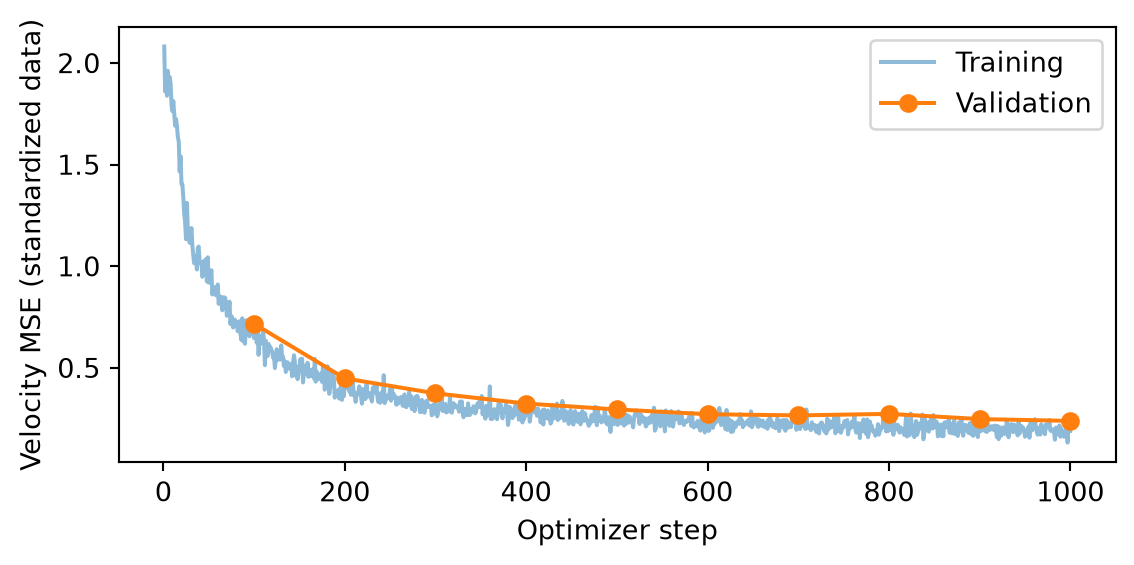

In [3]:
#| code-fold: true
#| code-summary: "Plot training and validation loss"
#| fig-cap: "Flow matching: training and validation loss for the bundled SIRDS bank."
validation = [row for row in model.history if "validation_loss" in row]
fig, ax = plt.subplots(figsize=(6, 3))
ax.plot([row["step"] for row in model.history],
        [row["train_loss"] for row in model.history], alpha=0.5, label="Training")
ax.plot([row["step"] for row in validation],
        [row["validation_loss"] for row in validation], "o-", label="Validation")
ax.set(xlabel="Optimizer step", ylabel="Velocity MSE (standardized data)")
ax.legend()
fig.tight_layout()
plt.show()

*Flow matching: training and validation loss for the bundled SIRDS bank.*

Generate several trajectories for the same held-out inputs by changing the
initial noise. The band below describes variation in surrogate samples, not
uncertainty in fitted model weights.

In [4]:
inputs = split.test.inputs[:1]
draws = model.sample(inputs, n_samples=100, seed=13, num_steps=30, solver="heun")[0]
print("Samples × times × outputs:", draws.shape)

/home/runner/work/metis/metis/src/metis/surrogate.py:737: UserWarning: Inputs outside the training ranges for ['I_0']; predictions extrapolate and are not clipped.
  array = self._inputs(inputs)


Samples × times × outputs: (100, 40, 4)


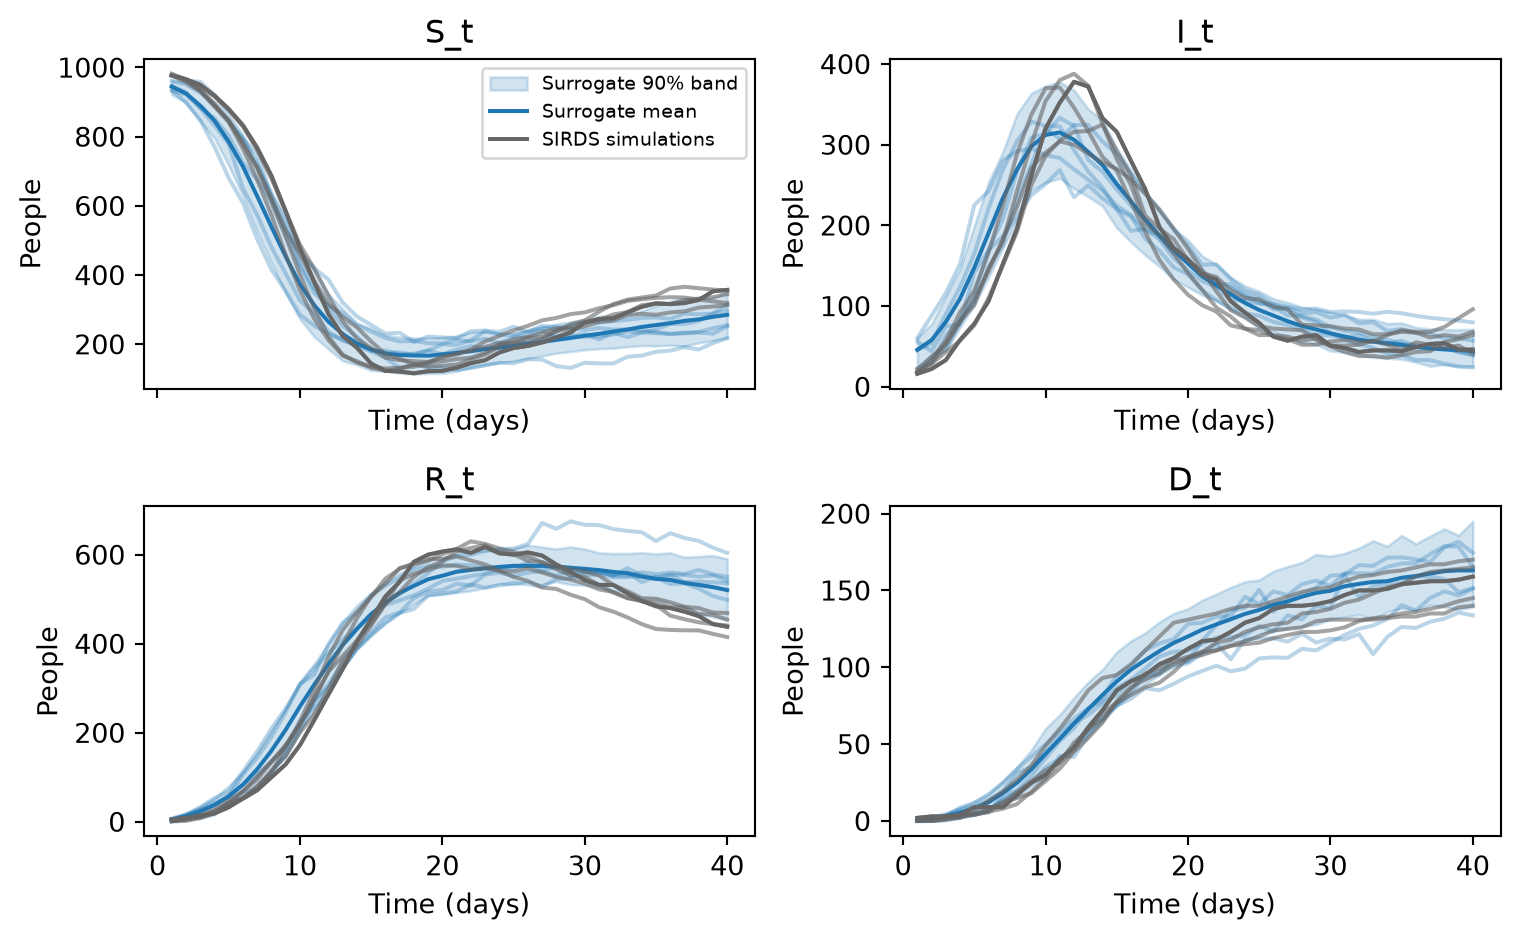

In [5]:
#| code-fold: true
#| code-summary: "Compare surrogate samples with SIRDS simulations"
#| fig-cap: "Flow matching: generated trajectories and five SIRDS simulations at the first held-out parameter setting. Shading spans the pointwise 5th–95th percentiles of 100 surrogate draws, after fitting the bundled SIRDS training split."
same_inputs = np.all(split.test.inputs == inputs[0], axis=1)
replicates = split.test.outputs[same_inputs]
low, high = np.quantile(draws, [0.05, 0.95], axis=0)
fig, axes = plt.subplots(2, 2, figsize=(8, 5), sharex=True)
for channel, ax in enumerate(axes.flat):
    ax.fill_between(bank.times, low[:, channel], high[:, channel],
                    color="C0", alpha=0.2, label="Surrogate 90% band")
    ax.plot(bank.times, draws[:5, :, channel].T, color="C0", alpha=0.3)
    ax.plot(bank.times, draws.mean(axis=0)[:, channel], color="C0", label="Surrogate mean")
    ax.plot(bank.times, replicates[:, :, channel].T, color="0.4", alpha=0.6)
    ax.plot(bank.times, replicates[0, :, channel], color="0.4", label="SIRDS simulations")
    ax.set(title=bank.output_names[channel], xlabel="Time (days)", ylabel="People")
axes[0, 0].legend(fontsize=7)
fig.tight_layout()
plt.show()

*Flow matching: generated trajectories and five SIRDS simulations at the first held-out parameter setting. Shading spans the pointwise 5th–95th percentiles of 100 surrogate draws, after fitting the bundled SIRDS training split.*

This short fit illustrates sampling; the plots show where it misses the SIRDS
trajectories. Check performance across the whole held-out bank before using a
surrogate in an application, as in the [training tutorial](https://ojwatson.github.io/metis/basics/training.html).

The [sequence conditioning example](https://ojwatson.github.io/metis/models/transformer.html#conditioning-on-an-observed-sequence)
also works with `Surrogate("flow_matching", observed_outputs=["I_t"])`:
fit that separate conditioned model on the SIRDS bank, construct the same
`new_inputs` and `infected_paths`, and call its `sample` method with
`conditioning={"I_t": infected_paths}`. Flow matching uses the entire supplied
infected trajectory to generate the other compartments, including observations
after each time point.